<a href="https://colab.research.google.com/github/BabuShaik778/Smart-Agricultural-Price-Forecasting-System/blob/main/AgriCast_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

import joblib

In [3]:
df = pd.read_csv("/content/price_data (2).csv")

df["date"] = pd.to_datetime(df["date"])
df["avg_monthly_price"] = pd.to_numeric(
    df["avg_monthly_price"], errors="coerce"
)

df = df.dropna().sort_values("date")

print(df.head())
print(df.info())

        date  avg_monthly_price
0 2005-01-01               5500
1 2005-02-01               5476
2 2005-03-01               5466
3 2005-04-01               5487
4 2005-05-01               5876
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               249 non-null    datetime64[ns]
 1   avg_monthly_price  249 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 4.0 KB
None


In [4]:
df = df.groupby(df["date"].dt.to_period("M"))[
    "avg_monthly_price"
].mean()

df.index = df.index.to_timestamp()

df = df.asfreq("MS").interpolate()

print("Missing values:", df.isnull().sum())
print("Total records:", len(df))

Missing values: 0
Total records: 249


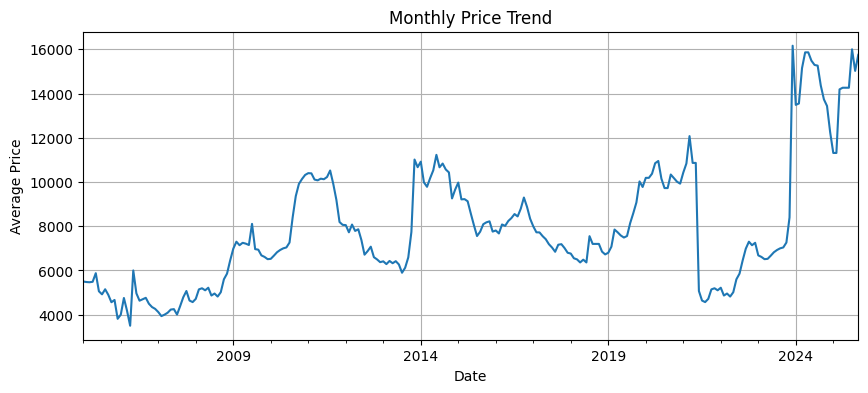

In [5]:
df.plot(figsize=(10, 4), title="Monthly Price Trend")

plt.xlabel("Date")
plt.ylabel("Average Price")
plt.grid()
plt.show()

In [7]:
data = pd.DataFrame({"price": df})

data["month"] = data.index.month
data["lag_1"] = data["price"].shift(1)
data["lag_3"] = data["price"].shift(3)
data["lag_12"] = data["price"].shift(12)

data = data.dropna()

X = data[["month", "lag_1", "lag_3", "lag_12"]]
y = data["price"]

print(X.head())

            month   lag_1   lag_3  lag_12
date                                     
2006-01-01      1  3813.0  4562.0  5500.0
2006-02-01      2  4000.0  4665.0  5476.0
2006-03-01      3  4755.0  3813.0  5466.0
2006-04-01      4  4176.0  4000.0  5487.0
2006-05-01      5  3500.0  4755.0  5876.0


In [8]:
split = len(data) - 12

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [9]:
rf = RandomForestRegressor(
    n_estimators=150,
    max_depth=5,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [10]:
xgb = XGBRegressor(
    n_estimators=150,
    max_depth=2,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

In [11]:
results = []

for name, pred in [
    ("Random Forest", rf_pred),
    ("XGBoost", xgb_pred)
]:
    mae = mean_absolute_error(y_test, pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, pred)
    )

    mape = np.mean(
        np.abs((y_test - pred) / y_test.replace(0, np.nan))
    ) * 100

    results.append([name, mae, rmse, mape])

results = pd.DataFrame(
    results,
    columns=["Model", "MAE", "RMSE", "MAPE"]
)

display(results)

best_name = results.loc[results["MAE"].idxmin(), "Model"]

best_model = rf if best_name == "Random Forest" else xgb

print("Best model:", best_name)

,Model,MAE,RMSE,MAPE
0,Random Forest,1881.175107,2691.634052,14.449603
1,XGBoost,1810.049316,2324.591982,13.123358


Best model: XGBoost


In [12]:
history = df.copy()
future = []

for i in range(12):

    next_date = history.index[-1] + pd.offsets.MonthBegin(1)

    features = pd.DataFrame([{
        "month": next_date.month,
        "lag_1": history.iloc[-1],
        "lag_3": history.iloc[-3],
        "lag_12": history.iloc[-12]
    }])

    predicted_price = best_model.predict(features)[0]

    future.append([next_date, predicted_price])

    history.loc[next_date] = predicted_price

forecast = pd.DataFrame(
    future,
    columns=["date", "predicted_price"]
)

display(forecast.round(2))

,date,predicted_price
0,2025-10-01,13376.820312
1,2025-11-01,10971.400391
2,2025-12-01,10119.969727
3,2026-01-01,7299.470215
4,2026-02-01,7240.790039
5,2026-03-01,7032.169922
6,2026-04-01,6590.669922
7,2026-05-01,6320.859863
8,2026-06-01,6036.740234
9,2026-07-01,5646.009766


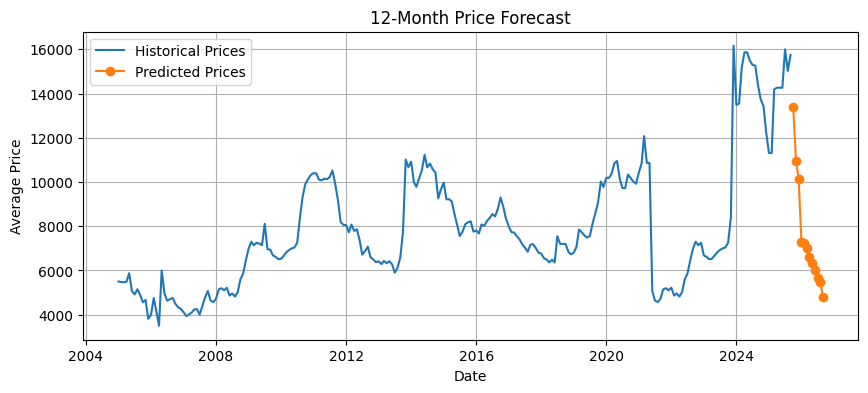

In [13]:
plt.figure(figsize=(10, 4))

plt.plot(df.index, df.values, label="Historical Prices")

plt.plot(
    forecast["date"],
    forecast["predicted_price"],
    marker="o",
    label="Predicted Prices"
)

plt.title("12-Month Price Forecast")
plt.xlabel("Date")
plt.ylabel("Average Price")

plt.legend()
plt.grid()
plt.show()

In [14]:
forecast.to_csv("price_forecast.csv", index=False)

print("Forecast saved successfully.")

Forecast saved successfully.


## Business Recommendations

1. If prices are expected to increase, consider early purchasing.
2. If prices are expected to decrease, review purchasing decisions.
3. Maintain sufficient inventory.
4. Use forecasts for purchasing and supply planning.
5. Monitor actual prices against predicted prices.

## Measuring Business Impact

The company can measure the effectiveness of its decisions by tracking:

- Purchase cost
- Inventory holding cost
- Stockouts
- Product wastage
- Forecast accuracy

Compare these business metrics before and after using
the forecasting system.

joblib.dump(best_model, "price_model.joblib")

print("ML model saved successfully.")

In [15]:
joblib.dump(best_model, "price_model.joblib")

print("ML model saved successfully.")

ML model saved successfully.


In [ ]:
from flask import Flask, request, jsonify
import joblib
import pandas as pd

app = Flask(__name__)

model = joblib.load("price_model.joblib")

@app.route("/predict", methods=["POST"])
def predict():

    prices = request.json["last_12_prices"]

    if len(prices) < 12:
        return jsonify({"error": "Provide 12 prices"}), 400

    features = pd.DataFrame([{
        "month": (pd.Timestamp.today().month),
        "lag_1": prices[-1],
        "lag_3": prices[-3],
        "lag_12": prices[-12]
    }])

    prediction = model.predict(features)[0]

    return jsonify({
        "predicted_price": round(float(prediction), 2)
    })

if __name__ == "__main__":
    app.run(debug=False)

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit


## Model Monitoring

1. Compare predicted prices with actual prices.
2. Calculate MAE and RMSE regularly.
3. Monitor changes in historical price patterns.
4. Retrain the model when prediction errors increase.
5. Store predictions and actual results for future evaluation.

## Conclusion

This project uses Machine Learning to analyze historical
monthly prices and forecast future prices.

Random Forest and XGBoost are trained and evaluated.
The model with the lowest MAE is selected.

The forecasting system can support purchasing,
inventory management and business planning.

The predictions are estimates and should be combined
with additional market information.